# Analysis of medical data for cardiovascular disease factors

Dataset: `medical_examination.csv` (70,000 raw rows). Keep the CSV beside this notebook and run the cells from top to bottom. Age is supplied in days; cholesterol and glucose are ordered categories, not concentration measurements. The original source and sampling method are not documented in the supplied CSV, which limits generalization.

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
from scipy.stats import zscore, levene
import pingouin as pg
import dcor as dc
import numpy as np
import statsmodels.api as stm
import statsmodels.formula.api as smf
from pygam import LinearGAM, s, f
from IPython.display import display

np.random.seed(2025)

In [2]:
medical_raw = pd.read_csv("medical_examination.csv")
medical = medical_raw.copy()
print(f"Raw dataset: {len(medical):,} rows")
print(f"Missing values: {medical.isna().sum().sum()}")
print(f"Duplicated patient ids: {medical['id'].duplicated().sum()}")

Raw dataset: 70,000 rows
Missing values: 0
Duplicated patient ids: 0


In [3]:
# ap_av is the arithmetic average of the two readings, not mean arterial pressure.
medical['ap_av'] = (medical['ap_hi'] + medical['ap_lo']) / 2
medical['bmi'] = medical['weight'] / (medical['height'] / 100) ** 2
medical['bmi'] = medical['bmi'].round(2)
medical['age'] = (medical['age'] / 365).round().astype(int)
medical_clean = medical[
    (medical['bmi'] >= 10) & (medical['bmi'] <= 60) &
    (medical['ap_hi'] >= 60) & (medical['ap_hi'] <= 250) &
    (medical['ap_lo'] >= 40) & (medical['ap_lo'] <= 180) &
    (medical['ap_lo'] < medical['ap_hi'])
].copy()

print(f"Removed {len(medical) - len(medical_clean):,} rows outside the selected limits.")
medical = medical_clean.copy()
print(f"Cleaned dataset: {len(medical):,} rows")
medical = medical.reindex(columns = ['id',	'age',	'gender',	'height',	'weight', 'bmi',	'ap_hi',	'ap_lo', 'ap_av',	'cholesterol',	'gluc',	'smoke',	'alco',	'active',	'cardio'])

Removed 1,395 rows outside the selected limits.
Cleaned dataset: 68,605 rows


In [4]:
medical = medical[medical['ap_hi'] >= medical['ap_lo']]
rows_before_gender_check = len(medical)
medical = medical[medical['gender'].isin([1, 2])]
print(f"Removed {rows_before_gender_check - len(medical)} rows with invalid gender codes.")
print(f"Final dataset: {len(medical):,} rows")
medical = medical.astype({
    'id': int,
    'age': int,
    'bmi':float,
    'ap_hi':float,
    'ap_lo':float,
    'ap_av':float,   
    'height': float,
    'weight': float,
    'cholesterol': int,
    'gluc': 'category',
    'gender': 'category',
    'smoke': 'category',
    'alco': 'category',
    'active': 'category',
    'cardio': 'category'    
})
bins = [0, 18.5, 25, 30, float('inf')]
labelsB = ['Underweight', 'Normal', 'Overweight', 'Obese']
scores = [0, 1, 2, 3]
medical["BMI_category"] = pd.cut(medical["bmi"], bins = bins, labels = labelsB, right = False)
medical['BMI_category'] = medical['BMI_category'].cat.set_categories(labelsB, ordered = True)
BMI_category = medical['BMI_category'].nbytes
bmi = medical['bmi'].nbytes
rel = round(medical['bmi'].nbytes/medical['BMI_category'].nbytes)
print(f'BMI_category (category) : {BMI_category} bytes',f"\nbmi (float) : {bmi} bytes", f'\n{rel} times less memory usage')

Removed 11 rows with invalid gender codes.
Final dataset: 68,594 rows
BMI_category (category) : 68626 bytes 
bmi (float) : 548752 bytes 
8 times less memory usage


In [5]:
labelsC = {1 : "Normal", 2 : "High", 3 : "Very high"}
labelsCs = ["Normal", "High", "Very High"]
labelsS = {0 : 'No', 1 : 'Yes'}
labelsA = {0 : "Non-drinker", 1 : "Drinks alcohol"}
labelsAC = {0 : "No", 1 : "Yes"}
labelsCa = {0 : "No", 1 : "Yes"}
labelsG = {1 : "Female", 2 : "Male"}
bins = [0, 18.5, 25, 30, float('inf')]
labelsBMI = ['Underweight', 'Normal', 'Overweight', 'Obese']
labelsC = {1: 'Normal', 2: 'High', 3: 'Very High'}
labelsCs = ['Normal', 'High', 'Very High']
medical['cholesterol_labeled'] = medical["cholesterol"].map(labelsC).astype('category').cat.set_categories(labelsCs, ordered=True)
medical['cholesterol_labeled'].head()
medical["smoke_labeled"] = medical["smoke"].map(labelsS)
medical["alco_labeled"] = medical["alco"].map(labelsA)
medical["activity_labeled"] = medical["active"].map(labelsAC)
medical["cardio_labeled"] = medical["cardio"].map(labelsCa)
medical["gender_labeled"] = medical["gender"].map(labelsG)
medical["bmi_labeled"] = pd.cut(medical["bmi"], bins = bins, labels = labelsBMI, right = False)
medical['bmi_labeled'] = medical['BMI_category'].cat.set_categories(labelsBMI, ordered = True)
medical = medical.astype({
    'id': int,
    'age': int,
    'bmi':float,
    'ap_hi':float,
    'ap_lo':float,
    'ap_av':float,   
    'height': float,
    'weight': float,
    'cholesterol': int,
    'gluc': int,
    'gender': int,
    'smoke': int,
    'alco': int,
    'active': int,
    'cardio': int    
})
medical = medical[(medical['weight'] > 0) & (medical['ap_lo'] > 0)]

Text(0.5, 1.0, 'General heatmap of correleation')

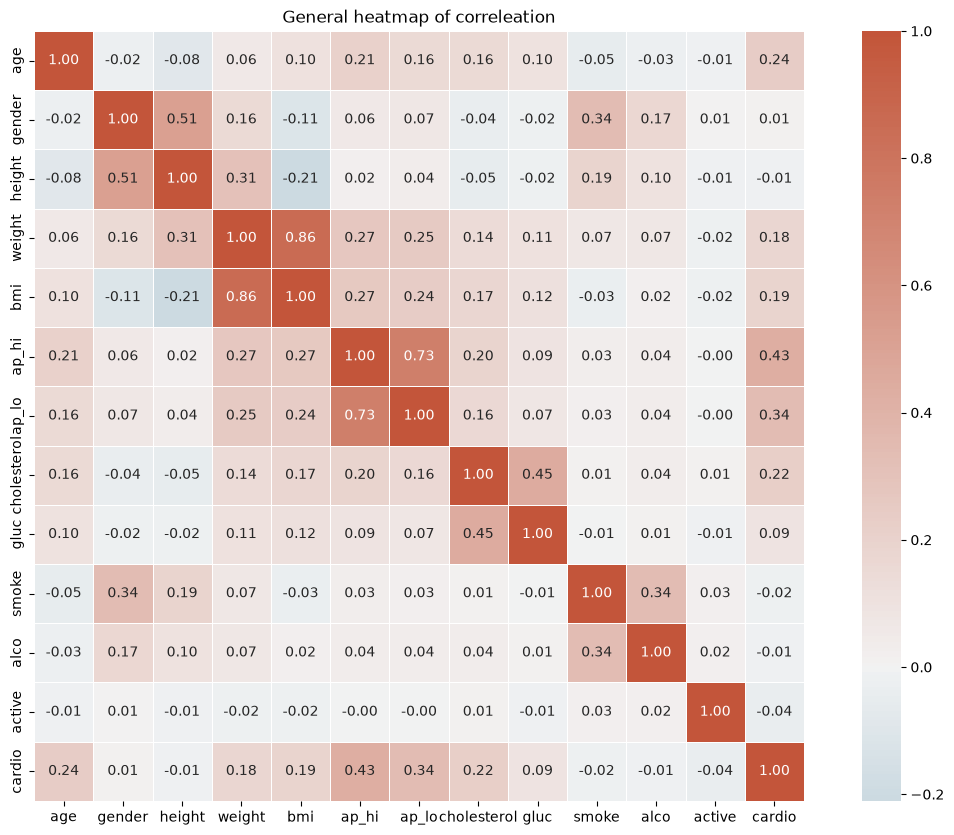

In [6]:
fig, ax = plt.subplots(figsize = [15, 10])
medheat = medical.select_dtypes(include = ['number']).drop(columns = ['id', 'ap_av']).corr()
cmap = sns.diverging_palette(230, 20, as_cmap=True)
ax = sns.heatmap(data = medheat, annot = True, fmt = '.2f', cmap = cmap, center = 0, square = True, linewidths=.5)
ax.set_title('General heatmap of correleation')

# Analysis of the heatmap

The present heatmap shows different correlations between health factors and lifestyle habits using data from the medical consultation dataframe. Most correlations are weak in this dataset. Let's overview the acceptable correlations we've got :  

- Body structure and composition

Weight and BMI (r ≈ 0.86):
Strong positive correlation, heavier individuals tend to have higher BMI. BMI is calculated from weight and height so this relationship is partly built into the formula.

Height and Gender (r ≈ 0.51):
Strong gender-height link, as men are generally taller than women in this dataset.

Height and BMI (r ≈ -0.21):
Slight negative relationship, taller people often have proportionally lower BMI.

These relationships follow expected patterns, though they don't validate every individual measurement.

- Cardiovascular indicators

Systolic and Diastolic blood pressure (r ≈ 0.73):
Strong positive correlation, when systolic rises, diastolic tends to rise too.

Age and Cardio (r ≈ 0.24):
Cardiovascular disease is more common at higher ages in this dataset.

Cholesterol and Glucose (r ≈ 0.45):
People with elevated cholesterol often have higher glucose levels, though these categories alone do not establish metabolic syndrome.

Weight, cholesterol and glucose categories are positively associated with diastolic pressure here, but this doesn't show that they cause it to increase.

These findings suggest that age and metabolic markers cluster among cardiovascular patients.

- Lifestyle effects

Gender and Smoke (r ≈ 0.34) and Gender and Alcohol (r ≈ 0.17):
Men show higher likelihood of smoking and alcohol consumption in this dataset for the sample being studied.

Active and Cardio (r ≈ –0.04):
Slight negative correlation, physically active individuals are marginally less likely to have cardiovascular disease, though weak.

These behavioral factors show weak unadjusted associations with disease status here.

- Variables with low or negligible correlations

Most off-diagonal values hover around 0.0–0.2, showing little direct linear relationship,
but weak pairwise correlations alone don't establish how these factors jointly relate to health outcomes.

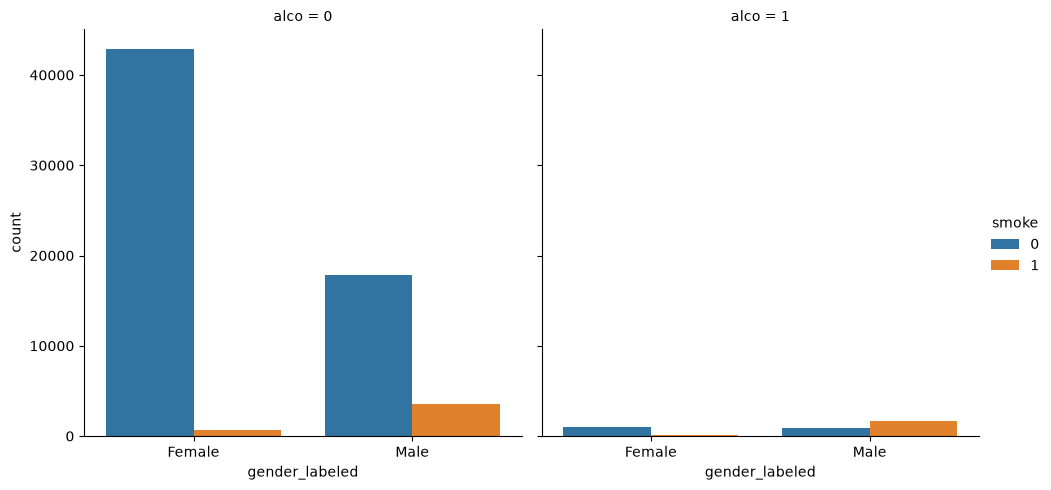

In [7]:
sns.catplot(data = medical, x = 'gender_labeled', hue = 'smoke', col = 'alco', kind = 'count')

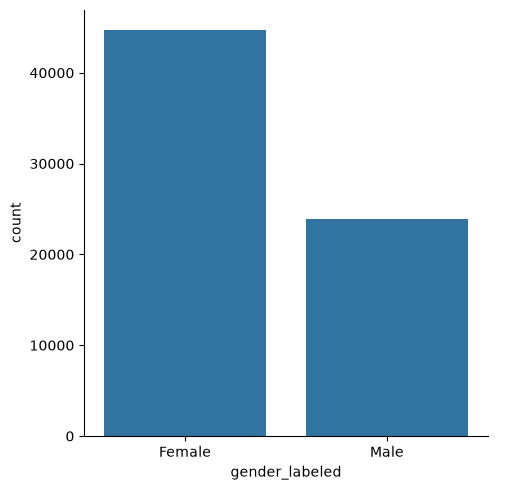

In [8]:
sns.catplot(data = medical, x = 'gender_labeled', kind = 'count')


The data could be biased as the number of males is about half the number of females. This imbalance alone does not prove bias, we would need to compare it with the population being studied.

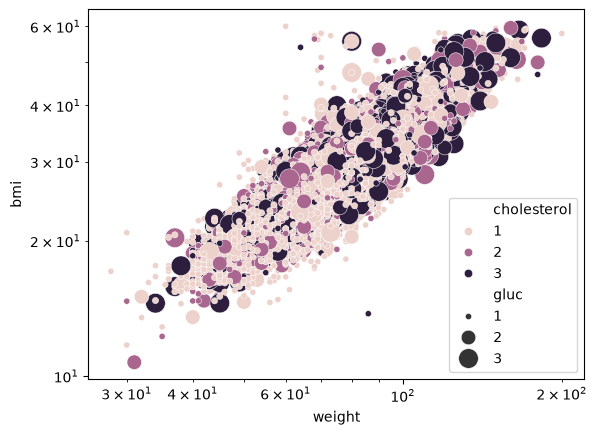

In [9]:
ax = sns.scatterplot(
    data=medical,
    x='weight',
    y='bmi',
    hue='cholesterol',
    size = 'gluc',
    sizes=(20, 200),
)
ax.set_xscale('log')
ax.set_yscale('log')
plt.show()

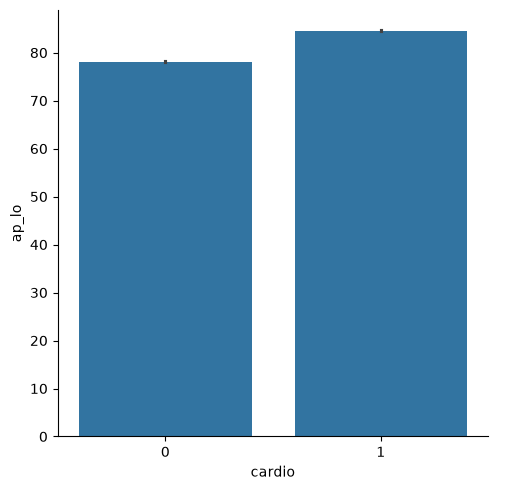

In [10]:
sns.catplot(x = 'cardio', y = 'ap_lo', kind = 'bar', seed=2025, data = medical)

# Statistics

In [11]:
medical[['age', 'height', 'weight', 'bmi', 'ap_lo', 'ap_hi', 'ap_av']].describe()

,age,height,weight,bmi,ap_lo,ap_hi,ap_av
count,68594.000000,68594.000000,68594.000000,68594.000000,68594.000000,68594.000000,68594.000000
mean,53.326545,164.410255,74.086843,27.448129,81.304210,126.670336,103.987273
std,6.767433,7.941467,14.213322,5.211774,9.445243,16.686775,12.240597
min,30.000000,100.000000,28.000000,10.730000,40.000000,60.000000,50.000000
25%,48.000000,159.000000,65.000000,23.880000,80.000000,120.000000,100.000000
50%,54.000000,165.000000,72.000000,26.350000,80.000000,120.000000,100.000000
75%,58.000000,170.000000,82.000000,30.120000,90.000000,140.000000,110.000000
max,65.000000,250.000000,200.000000,60.000000,180.000000,240.000000,190.000000


**Age** : The minimal age is 30 years old, most of them are middle aged.

**BMI** : most patients here seems to be overweight or obese as the mean is 27.4, the median is 26.4, and the first quarter highest is quit close to 25.

<Axes: xlabel='cholesterol', ylabel='weight'>

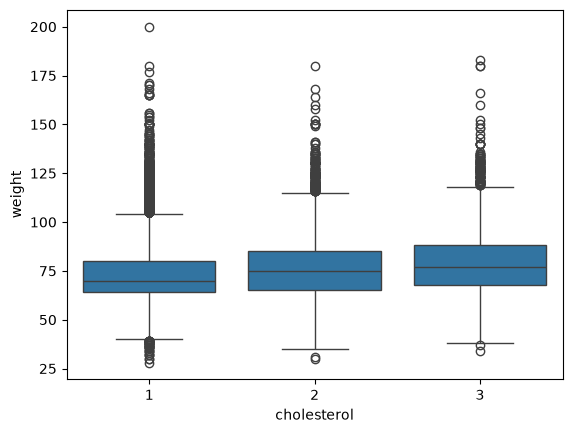

In [12]:
sns.boxplot(data = medical, x = 'cholesterol', y ='weight')

In [13]:
medical.shape

(68594, 23)

High amount of **outliers**, classic in **biomedical** fields. We shouldn't erase them just because they are unusual. Here we use the BMI and blood pressure limits chosen above for the analysis, though these limits do not mean every excluded value is physiologically impossible. So we keep the other unusual values as outliers are interesting for biomedical research and data analysis in this field. Some retained measurements may still need checking.

# Some comments on the data
## 1. Differences  

In [14]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
# Keep the cleaned dataframe and its derived columns from the first section.

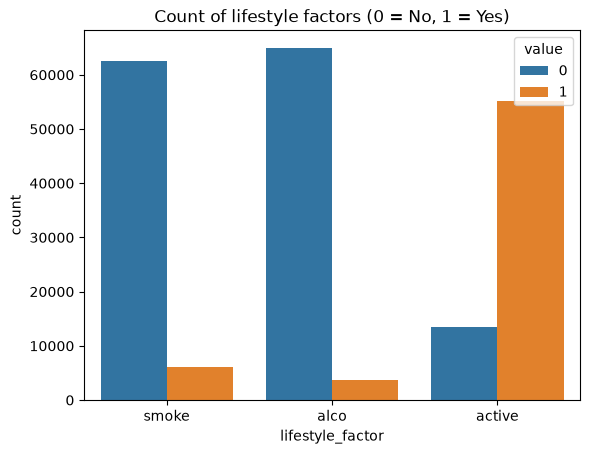

In [15]:
melted = medical.melt(value_vars=['smoke', 'alco', 'active'],
                      var_name='lifestyle_factor', value_name='value')

sns.countplot(data=melted, x='lifestyle_factor', hue='value')
plt.title('Count of lifestyle factors (0 = No, 1 = Yes)')
plt.show()

We see a big difference between the number of people that do have the habit of smoking and drinking alcohol and those who don't. There is still a difference between the active and non-active populations but it is not as big. 
This difference reflects how common those habits are in the population being studied.

* Most people don’t smoke.

* Most people are recorded as not drinking alcohol.

* Many people might be physically active.

## 2.Outliers

In [16]:
medical_raw['ap_hi'].min() 

np.int64(-150)

In [17]:
medical_raw['ap_hi'].max() 

np.int64(16020)

We see some outliers in the raw data that need to be checked. We already applied the selected limits at the beginning. And after that we can analyse the blood pressure.

In [18]:
# The same cleaned dataset is used throughout the analysis.
medical[["ap_hi", "ap_lo", "ap_av"]].describe()

,ap_hi,ap_lo,ap_av
count,68594.000000,68594.000000,68594.000000
mean,126.670336,81.304210,103.987273
std,16.686775,9.445243,12.240597
min,60.000000,40.000000,50.000000
25%,120.000000,80.000000,100.000000
50%,120.000000,80.000000,100.000000
75%,140.000000,90.000000,110.000000
max,240.000000,180.000000,190.000000


# Analysing the data 

## Blood pressure

Text(4.444444444444445, 0.5, 'high arterial pressure')

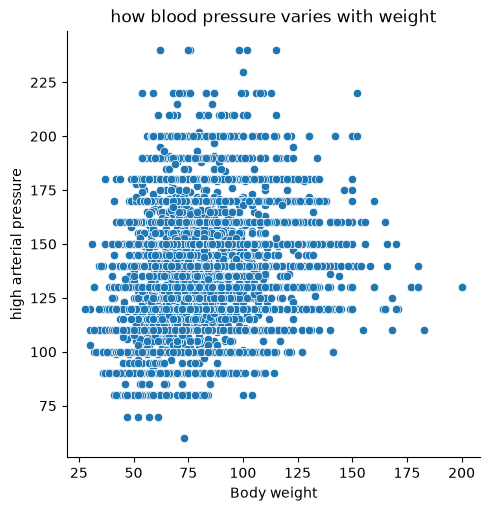

In [19]:
sns.relplot (data = medical, x ='weight', y= 'ap_hi')
plt.title('how blood pressure varies with weight')
plt.xlabel("Body weight")
plt.ylabel("high arterial pressure")

We can see that most people are average, in the middle. There’s a dense cluster in the middle: roughly between 60–90 kg weight and 80–140 mmHg pressure.

There’s some positive trend,as weight increases the average blood pressure tends to increase slightly.
But we can see that the relationship isn’t perfectly linear. Many people with the same weight have quite different blood pressures. This shows weight is associated with blood pressure here, but it does not explain all the differences.
We can still see some outliers for example:
Very high ap_hi (>160) or low ap_hi near 60. those are unusually high or low systolic pressures in this sample, not body weights.

Text(37.28655555555555, 0.5, 'high arterial pressure')

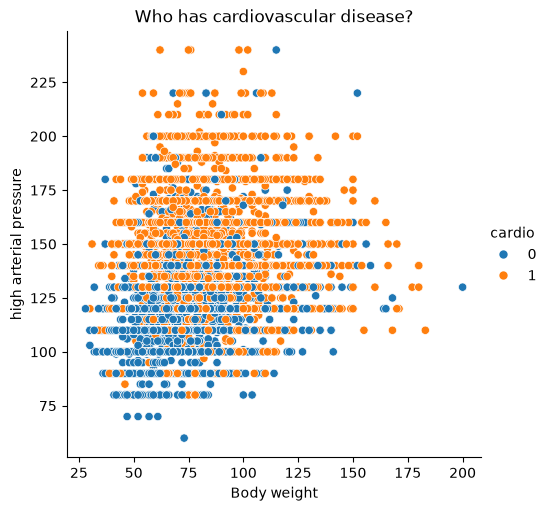

In [20]:
sns.relplot(data=medical, x='weight', y='ap_hi', hue='cardio', kind='scatter')
plt.title('Who has cardiovascular disease?')
plt.xlabel("Body weight")
plt.ylabel("high arterial pressure")

People with cardiovascular disease tend to cluster at higher weights and blood pressures.

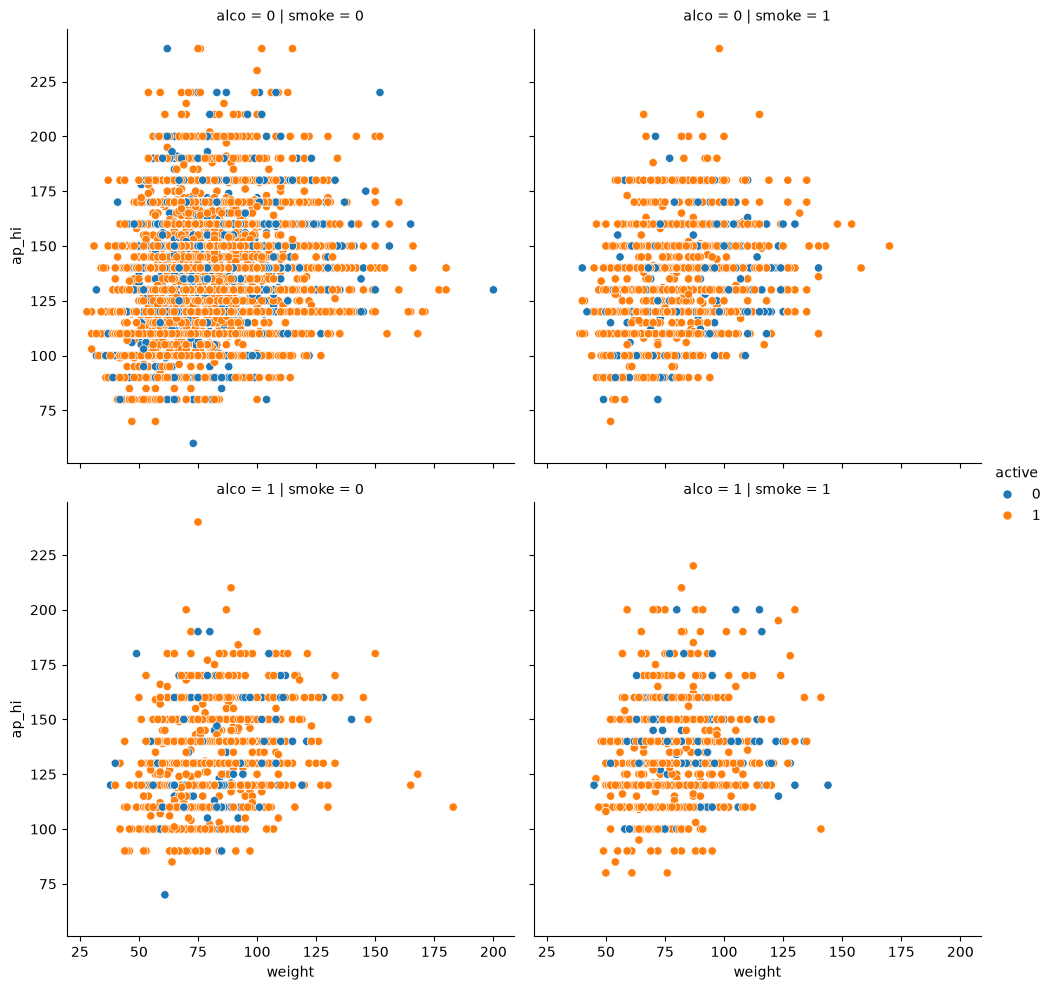

In [21]:
sns.relplot(
    data=medical,
    x='weight',
    y='ap_hi',
    col='smoke',
    row='alco',
    hue='active'
)
plt.show()

Across all plots, there’s a weak positive correlation. As weight increases, blood pressure tends to increase slightly. In the data set we have few smokers/drinkers this is why it is hard to detect differences. But these plots alone do not show a clear independent effect of smoking and drinking, other differences between the groups could play a role.

## Cholesterol

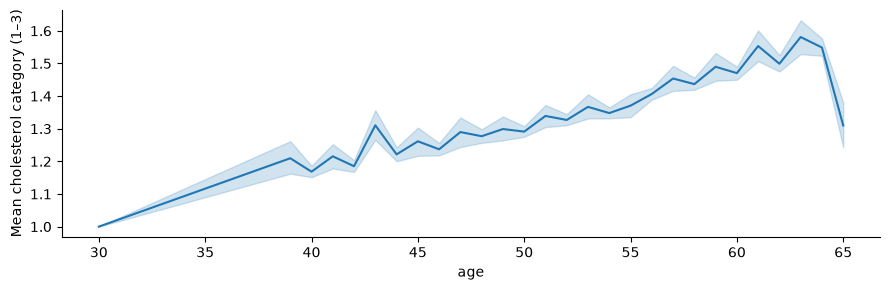

In [22]:
# Age was already converted from days to years in the first section.

sns.relplot(kind = 'line', seed=2025, data = medical, estimator = 'mean', x = 'age', y='cholesterol',height= 3, aspect= 3 )
plt.ylabel("Mean cholesterol category (1–3)")
plt.show()

We can see that the average cholesterol category tends to increase with age. These values are ordered categories, not measured cholesterol concentrations. We see a sharp decline around 65 but this group is much smaller (342 people). This could reflect the sample, we cannot conclude it is a biological trend.

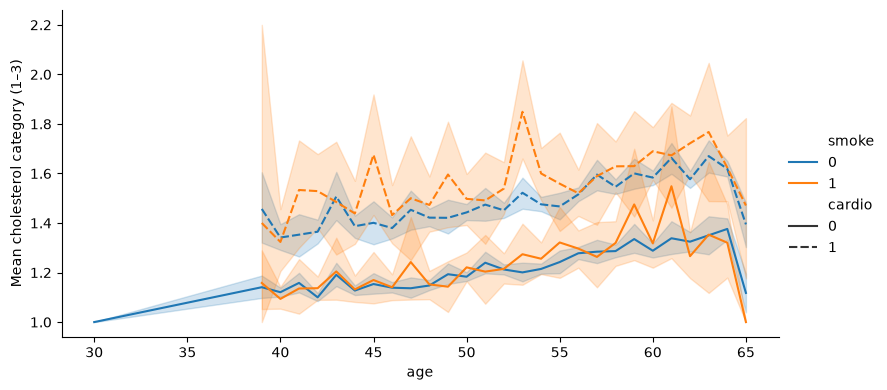

In [23]:
sns.relplot(kind = 'line', seed=2025, data = medical, x = 'age', y='cholesterol', hue ='smoke',style ='cardio', height= 4, aspect= 2,)
plt.ylabel("Mean cholesterol category (1–3)")
plt.show()

There is a noticeable difference in the cholesterol levels in people who have cardiovascular disease and people without recorded cardiovascular disease. We can compare it to another factor, which is smoking. Smokers show slightly higher average cholesterol categories in both groups but the difference is smaller than between cardiovascular disease groups. This highlights an association, it does not show which factor causes the other.

### Welch's ANOVA

As our dataset is huge (**more than 68,000 rows**), the **central limit theory** helps approximate the sampling distribution of group means to the **normal distribution**, assuming independent observations and sufficient observations in each group. The data itself does not become normal, so we still need to check outliers and group sizes. Now we are going to use **Levene test** to check if the variances are equal.

In [24]:
carlo = levene(
    medical.loc[medical['cardio']==0, 'ap_lo'],
    medical.loc[medical['cardio']==1, 'ap_lo']
)
cholbmi = levene(
    medical.loc[medical['cholesterol']== 1, 'bmi'],
    medical.loc[medical['cholesterol']==2, 'bmi'],
    medical.loc[medical['cholesterol'] == 3, 'bmi' ]
)
carhi = levene(
    medical.loc[medical['cardio']==0, 'ap_hi'],
    medical.loc[medical['cardio']==1, 'ap_hi']
)
carage = levene(
    medical.loc[medical['cardio']==0, 'age'],
    medical.loc[medical['cardio']==1, 'age']
)
bmhi = levene(
    medical.loc[medical['bmi_labeled'] == 'Underweight', 'ap_hi'],
    medical.loc[medical['bmi_labeled'] == 'Normal', 'ap_hi'],
    medical.loc[medical['bmi_labeled'] == 'Overweight', 'ap_hi'],
    medical.loc[medical['bmi_labeled'] == 'Obese', 'ap_hi']
)
bmlo = levene (
     medical.loc[medical['bmi_labeled'] == 'Underweight', 'ap_lo'],
    medical.loc[medical['bmi_labeled'] == 'Normal', 'ap_lo'],
    medical.loc[medical['bmi_labeled'] == 'Overweight', 'ap_lo'],
    medical.loc[medical['bmi_labeled'] == 'Obese', 'ap_lo']
)
print(cholbmi)
print(carlo)
print(carhi)
print(carage)
print(bmhi)
print(bmlo)

LeveneResult(statistic=np.float64(274.30981919189014), pvalue=np.float64(2.201226503774386e-119))
LeveneResult(statistic=np.float64(1559.8044848540358), pvalue=np.float64(0.0))
LeveneResult(statistic=np.float64(5753.559937834615), pvalue=np.float64(0.0))
LeveneResult(statistic=np.float64(260.97026429612697), pvalue=np.float64(1.3532470952779108e-58))
LeveneResult(statistic=np.float64(563.9008153813561), pvalue=np.float64(0.0))
LeveneResult(statistic=np.float64(274.13516855542315), pvalue=np.float64(6.862447060347012e-177))


P-val is inferior to the risk alpha 0.05 which means  :

there is evidence that the **variances aren't equal** here, so ordinary **ANOVA** may be less suitable. Fortunately, there's an alternative in this case called **Welch's ANOVA** which automatically adjusts to this case.

Welch's ANOVA helps us to test **group mean differences**.

In [25]:
welch_bmi_chol = pg.welch_anova(data = medical, dv = 'bmi', between = 'cholesterol')
welch_bmi_chol

,Source,ddof1,ddof2,F,p_unc,np2
0,cholesterol,2,13980.901207,914.171948,0.0,0.030213


| Metric           | Value         | Interpretation |
| :--------------- | :------------ | :------------- |
| **F**            | 914.2 | Large F → evidence of group mean differences relative to the uncertainty in the means |
| **p-unc**        | < 0.001 | p ≪ 0.05 → statistically significant; a displayed 0.0 is numerical rounding or underflow, not an exact zero |
| **ηp²**          | 0.030 | Partial eta-squared → **small effect** (≈ 3.0 % of BMI variation associated with cholesterol category in this one-factor comparison) |

People with higher cholesterol levels tend to have higher average BMI, though other factors also play a much larger role, as the effect size (ηp² = 0.030) suggests that cholesterol category is associated with about 3.0 % of the variance in BMI. This is not a causal explanation.
BMI is used here instead of the weight to account for height, as tall people can be heavier but not really being overweight.

In [26]:
welch_lo_cardio = pg.welch_anova(data=medical, dv='ap_lo', between= 'cardio') 
welch_lo_cardio

,Source,ddof1,ddof2,F,p_unc,np2
0,cardio,1,66439.248848,8944.369407,0.0,0.1157


The relationship between diastolic pressure and cardiovascular diseases is statistically significant with ηp² ≈ 0.116. Cardiovascular disesases category is associated with about **11.6%** of the variance in **diastolic pressure** in this one-factor comparison, without showing causation.

In [27]:
welch_hi_cardio = pg.welch_anova(data=medical, dv='ap_hi', between= 'cardio') 
welch_hi_cardio

,Source,ddof1,ddof2,F,p_unc,np2
0,cardio,1,61918.575469,15282.391893,0.0,0.183175


Here, we see a higher association with **systolic pressure** across cardiovascular diseases categories. The relationship here is statistically significant and cardiovascular disease status is associated with about **18.3%** of variance in ap_hi or systolic pressure in this one-factor comparison.

In [28]:
welch_age_cardio = pg.welch_anova(data = medical, dv = 'age', between = 'cardio')
welch_age_cardio

,Source,ddof1,ddof2,F,p_unc,np2
0,cardio,1,68454.650627,4167.584421,0.0,0.057204


High F, statisticaly significant relationship with about **5.7 %** of age variation associated with cardiovascular disease status in this one-factor comparison.

In [29]:
welch_hi_bmi = pg.welch_anova(data = medical, dv = 'ap_hi', between = 'bmi_labeled')
welch_hi_bmi

,Source,ddof1,ddof2,F,p_unc,np2
0,bmi_labeled,3,3083.98136,1478.301872,0.0,0.063623


In [30]:
welch_lo_bmi = pg.welch_anova(data = medical, dv = 'ap_lo', between = 'bmi_labeled')
welch_lo_bmi

,Source,ddof1,ddof2,F,p_unc,np2
0,bmi_labeled,3,3077.606145,1210.2273,0.0,0.052195


Small effects of 6.4% and 5.2% are observed for BMI categories and systolic and diastolic pressure. These are unadjusted associations.

In [31]:
# Pairwise differences in systolic pressure between cholesterol categories.
cholesterol_pairs = pg.pairwise_gameshowell(
    data=medical, dv='ap_hi', between='cholesterol', effsize='cohen'
)
cholesterol_pairs

,A,B,mean_A,mean_B,diff,se,T,df,pval,cohen
0,1,2,124.816452,130.863230,-6.046779,0.211763,-28.554397,11618.440626,1.006817e-11,-0.370949
1,1,3,124.816452,133.840305,-9.023854,0.201663,-44.747296,10077.623395,0.000000e+00,-0.569340
2,2,3,130.863230,133.840305,-2.977075,0.275550,-10.804132,17142.237153,9.260592e-12,-0.163652


Systolic blood pressure differs significantly between cholesterol categories (p < 0.001 for all pairwise Games–Howell comparisons).
The effect is smaller between normal and high cholesterol (Cohen’s d ≈ 0.37) than between normal and very high cholesterol (d ≈ 0.57), and smaller between the two elevated categories (d ≈ 0.16).
This suggests that average blood pressure is higher in the elevated cholesterol categories. These are differences between groups, not changes measured in the same patients over time.

### ANCOVA

ANCOVA studies **group mean differences** while adjusting for a covariante. Unlike Welch's ANOVA, ordinary ANCOVA does not automatically handle unequal variances. Here we also show a table using HC3 standard errors, and check if the relationship with systolic pressure has the same slope in each cholesterol group.

In [32]:
ancova = pg.ancova(data=medical, dv='ap_lo', covar='ap_hi', between='cholesterol')
display(ancova)

# HC3 standard errors allow for unequal residual variances.
ancova_model = smf.ols('ap_lo ~ ap_hi + C(cholesterol)', data=medical).fit()
print(f"Full model R² = {ancova_model.rsquared:.3f}")
display(stm.stats.anova_lm(ancova_model, typ=2, robust='hc3'))

# Check the common-slope assumption too.
interaction_model = smf.ols('ap_lo ~ ap_hi * C(cholesterol)', data=medical).fit(cov_type='HC3')
interaction_test = interaction_model.wald_test_terms(scalar=True).table.loc[['ap_hi:C(cholesterol)']]
display(interaction_test)

,Source,SS,DF,F,p_unc,np2
0,cholesterol,2.266764e+03,2,27.647024,9.951466e-13,0.000806
1,ap_hi,3.146420e+06,1,76751.830315,0.000000e+00,0.528078
2,Residual,2.811828e+06,68590,NaN,NaN,NaN


Full model R² = 0.541


,sum_sq,df,F,PR(>F)
C(cholesterol),2.006945e+03,2.0,24.478088,2.360987e-11
ap_hi,1.491172e+06,1.0,36374.726680,0.000000e+00
Residual,2.811828e+06,68590.0,NaN,NaN


,statistic,pvalue,df_constraint
ap_hi:C(cholesterol),20.87393,0.000029,2


Systolic BP has partial ηp² ≈ **0.528** after accounting for cholesterol category. This is a partial effect size, not the percentage of total diatolic BP variance explained by systolic BP alone. The full model R² is **0.541**. They are **tightly linked**.

The interaction check gives p = **2.93e-05**, which suggests the slopes differ across cholesterol groups. So the common-slope ANCOVA table should be read as a simplified exploratory model.

### Chi 2 independence

Now as ANOVA needs a **continuous dependant variable**, we use another test to examine the statistical relationship between two categorical variables.

The test that could help us to do so is called **chi2 test of independance**.

As the contingency tables are built from frequencies (counts), not proportions, and all the **expected cell counts** are >= 5 here, then

we can use a **chi2 test of independence** to test associations between categories, assuming each row is an independent observation. The p-values below are unadjusted across the different associations tested.

In [33]:
expected, observed, chi_smoke = pg.chi2_independence(data=medical, x='smoke', y='cardio')
display(pd.crosstab(medical['smoke'], medical['cardio']))
chi_smoke

cardio,0,1
smoke,,
0,31451,31108
1,3207,2828


,test,lambda,chi2,dof,pval,cramer,power
0,pearson,1.000000,17.969915,1.0,0.000022,0.016186,0.988670
1,cressie-read,0.666667,17.973548,1.0,0.000022,0.016187,0.988683
2,log-likelihood,0.000000,17.983298,1.0,0.000022,0.016192,0.988717
3,freeman-tukey,-0.500000,17.992790,1.0,0.000022,0.016196,0.988750
4,mod-log-likelihood,-1.000000,18.004153,1.0,0.000022,0.016201,0.988790
5,neyman,-2.000000,18.032513,1.0,0.000022,0.016214,0.988888


In [34]:
# Cramér's V is reported directly, not as a percentage.
chi_smoke.loc[chi_smoke['test'] == 'pearson', 'cramer'].iloc[0]

np.float64(0.016185642644612728)

**p-value** = 2.24e-05 < 0.05,  so we **reject H₀**, **smoking** status and **cardiovascular disease** are **not independent** as there is a statistically significant association.

**Cramér’s V** ≈ 0.016, a **very small effect size**, even though it’s statistically significant with this large sample size. This is a weak unadjusted association in this dataset, not evidence that smoking is harmless. V is reported directly, not as a percentage of variance explained.

In [35]:
expected, observed, chi_alco = pg.chi2_independence(data=medical, x='alco', y='cardio')
display(pd.crosstab(medical['alco'], medical['cardio']))
chi_alco

cardio,0,1
alco,,
0,32744,32191
1,1914,1745


,test,lambda,chi2,dof,pval,cramer,power
0,pearson,1.000000,4.841074,1.0,0.027790,0.008401,0.594959
1,cressie-read,0.666667,4.841665,1.0,0.027780,0.008401,0.595011
2,log-likelihood,0.000000,4.843167,1.0,0.027756,0.008403,0.595144
3,freeman-tukey,-0.500000,4.844573,1.0,0.027733,0.008404,0.595267
4,mod-log-likelihood,-1.000000,4.846220,1.0,0.027707,0.008405,0.595412
5,neyman,-2.000000,4.850237,1.0,0.027642,0.008409,0.595766


In [36]:
# Cramér's V is reported directly, not as a percentage.
chi_alco.loc[chi_alco['test'] == 'pearson', 'cramer'].iloc[0]

np.float64(0.00840093797619944)

Statistically significant at the unadjusted 0.05 level, but very low effect with Cramér’s V ≈ 0.008 which makes the observed association **very weak**. This doesn't show that alcohol has little effect on health.

In [37]:
expected, observed, chi_active = pg.chi2_independence(data=medical, x='active', y='cardio')
display(pd.crosstab(medical['active'], medical['cardio']))
chi_active

cardio,0,1
active,,
0,6305,7187
1,28353,26749


,test,lambda,chi2,dof,pval,cramer,power
0,pearson,1.000000,96.572320,1.0,8.604284e-23,0.037522,1.0
1,cressie-read,0.666667,96.576155,1.0,8.587632e-23,0.037523,1.0
2,log-likelihood,0.000000,96.609011,1.0,8.446299e-23,0.037529,1.0
3,freeman-tukey,-0.500000,96.655724,1.0,8.249353e-23,0.037538,1.0
4,mod-log-likelihood,-1.000000,96.721401,1.0,7.980201e-23,0.037551,1.0
5,neyman,-2.000000,96.909863,1.0,7.255635e-23,0.037587,1.0


In [38]:
# Cramér's V is reported directly, not as a percentage.
chi_active.loc[chi_active['test'] == 'pearson', 'cramer'].iloc[0]

np.float64(0.03752176567673158)

This one is also statistically significant, but the unadjusted association is very small (Cramér’s V ≈ 0.038).

In [39]:
expected, observed, chi_gluc_chol = pg.chi2_independence(data=medical, x='gluc', y='cholesterol')
display(pd.crosstab(medical['gluc'], medical['cholesterol']))
chi_gluc_chol

cholesterol,1,2,3
gluc,,,
1,47782,6555,3979
2,2197,2367,501
3,1457,371,3385


,test,lambda,chi2,dof,pval,cramer,power
0,pearson,1.000000,21198.789783,4.0,0.0,0.393095,1.0
1,cressie-read,0.666667,17700.211475,4.0,0.0,0.359196,1.0
2,log-likelihood,0.000000,13586.270706,4.0,0.0,0.314697,1.0
3,freeman-tukey,-0.500000,12045.161393,4.0,0.0,0.296311,1.0
4,mod-log-likelihood,-1.000000,11321.871780,4.0,0.0,0.287277,1.0
5,neyman,-2.000000,11559.959972,4.0,0.0,0.290282,1.0


In [40]:
# Cramér's V is reported directly, not as a percentage.
chi_gluc_chol.loc[chi_gluc_chol['test'] == 'pearson', 'cramer'].iloc[0]

np.float64(0.3930949564718306)

Here we have a statistically significant and larger association with Cramér’s V ≈ **0.393**. This is not a percentage of shared variance.

In [41]:
expected, observed, chi_cardio_gluc = pg.chi2_independence(data=medical, x='cardio', y='gluc')
display(pd.crosstab(medical['cardio'], medical['gluc']))
chi_cardio_gluc

gluc,1,2,3
cardio,,,
0,30580,2084,1994
1,27736,2981,3219


,test,lambda,chi2,dof,pval,cramer,power
0,pearson,1.000000,577.881608,2.0,3.270418e-126,0.091786,1.0
1,cressie-read,0.666667,578.578765,2.0,2.307903e-126,0.091841,1.0
2,log-likelihood,0.000000,581.423061,2.0,5.566554e-127,0.092067,1.0
3,freeman-tukey,-0.500000,584.852201,2.0,1.002209e-127,0.092338,1.0
4,mod-log-likelihood,-1.000000,589.425302,2.0,1.018408e-128,0.092698,1.0
5,neyman,-2.000000,602.159970,2.0,1.748332e-131,0.093694,1.0


In [42]:
# Cramér's V is reported directly, not as a percentage.
chi_cardio_gluc.loc[chi_cardio_gluc['test'] == 'pearson', 'cramer'].iloc[0]

np.float64(0.09178598472858257)

The relationship here is statistically significant, but the association is small (Cramér’s V ≈ 0.092).

In [43]:
expected, observed, chi_cardio_chol = pg.chi2_independence(data=medical, x='cardio', y='cholesterol')
display(pd.crosstab(medical['cardio'], medical['cholesterol']))
chi_cardio_chol

cholesterol,1,2,3
cardio,,,
0,29038,3752,1868
1,22398,5541,5997


,test,lambda,chi2,dof,pval,cramer,power
0,pearson,1.000000,3362.007532,2.0,0.0,0.221389,1.0
1,cressie-read,0.666667,3385.875470,2.0,0.0,0.222174,1.0
2,log-likelihood,0.000000,3478.703118,2.0,0.0,0.225199,1.0
3,freeman-tukey,-0.500000,3593.106477,2.0,0.0,0.228872,1.0
4,mod-log-likelihood,-1.000000,3752.929180,2.0,0.0,0.233906,1.0
5,neyman,-2.000000,4246.762124,2.0,0.0,0.248820,1.0


In [44]:
# Cramér's V is reported directly, not as a percentage.
chi_cardio_chol.loc[chi_cardio_chol['test'] == 'pearson', 'cramer'].iloc[0]

np.float64(0.22138912126292185)

The association has Cramér’s V ≈ **0.221**, which is larger than the lifestyle associations here.

In [45]:
expected, observed, chi_bmi_chol = pg.chi2_independence(data=medical, x='bmi_labeled', y='cholesterol')
display(pd.crosstab(medical['bmi_labeled'], medical['cholesterol']))
chi_bmi_chol

cholesterol,1,2,3
bmi_labeled,,,
Underweight,526,72,34
Normal,20827,2577,1887
Overweight,18584,3443,2678
Obese,11499,3201,3266


,test,lambda,chi2,dof,pval,cramer,power
0,pearson,1.000000,2023.601643,6.0,0.0,0.121452,1.0
1,cressie-read,0.666667,2003.612643,6.0,0.0,0.120851,1.0
2,log-likelihood,0.000000,1978.827909,6.0,0.0,0.120101,1.0
3,freeman-tukey,-0.500000,1973.058890,6.0,0.0,0.119926,1.0
4,mod-log-likelihood,-1.000000,1978.068925,6.0,0.0,0.120078,1.0
5,neyman,-2.000000,2020.841341,6.0,0.0,0.121369,1.0


In [46]:
# Cramér's V is reported directly, not as a percentage.
chi_bmi_chol.loc[chi_bmi_chol['test'] == 'pearson', 'cramer'].iloc[0]

np.float64(0.1214519380169588)

The association is quite small (Cramér’s V ≈ 0.121).

### Distance correlation

**Distance correlation** measures any dependancy shape so it could detect **subtle patterns** a linear correlation could miss. It can be used with numeric random variables or vectors, not only **continuous** variables. Here we use it for BMI, age and blood pressure.

In [47]:
dcor_bmi_hi = dc.distance_correlation(
    medical['bmi'].to_numpy(dtype=float),
    medical['ap_hi'].to_numpy(dtype=float)
)
dcor_bmi_hi

np.float64(0.26653783414745563)

In [48]:
dcor_bmi_lo = dc.distance_correlation(
    medical['bmi'].to_numpy(dtype=float),
    medical['ap_lo'].to_numpy(dtype=float)
)
dcor_bmi_lo

np.float64(0.22882523448623104)

In [49]:
dcor_age_hi = dc.distance_correlation(
    medical['age'].to_numpy(dtype=float),
    medical['ap_hi'].to_numpy(dtype=float)
)
dcor_age_hi

np.float64(0.19946191176088446)

In [50]:
dcor_age_lo = dc.distance_correlation(
    medical['age'].to_numpy(dtype=float),
    medical['ap_lo'].to_numpy(dtype=float)
)
dcor_age_lo

np.float64(0.14891866436255713)

Distance correlation captures **any dependency shape, linear or nonlinear**.

The population distance correlation equals 0 only when variables are **truly independent**, assuming finite first moments, and scales up to 1. A sample estimate alone does not prove independence or dependence.

Here we have a dependency (distance correlation about 0.267) between BMI and blood pressure, systolic in this exemple.

This value cannot be directly compared with ηp² from Welch's ANOVA or interpreted as a linear r. So, this difference alone does not establish a **nonlinear** pattern or an **obesity** threshold.

BMI and systolic pressure have a **general dependency**, but distance correlation alone does not show the shape or direction of it.

Also, the distance correlations with age are lower here (about 0.199 systolic and 0.149 diastolic) than those with BMI (0.267 and 0.229).

So, we conclude here that **BMI** has a **mesurable association** with **blood pressure**, without showing causation.

### Glass's delta

This effect size measure compares **2 groups** like 'cardio', using the standard deviation of the reference group. Here the reference is cardio = 0.

In [51]:
group0 = medical.loc[medical['cardio']==0, 'ap_hi']
group1 = medical.loc[medical['cardio']==1, 'ap_hi']

glass_delta = (np.mean(group1) - np.mean(group0)) / np.std(group0, ddof=1)
print("Glass's delta =", glass_delta)

Glass's delta = 1.1369393815576536


This is a large standardized difference in this sample. Clinical meaning would need more context, not only the effect size.

In [52]:
group0 = medical.loc[medical['cardio']==0, 'ap_lo']
group1 = medical.loc[medical['cardio']==1, 'ap_lo']

glass_delta = (np.mean(group1) - np.mean(group0)) / np.std(group0, ddof=1)
print("Glass's delta =", glass_delta)

Glass's delta = 0.7883338827445545


This one is strong too but not as much as the previous one

In [53]:
group0 = medical.loc[medical['cardio']==0, 'bmi']
group1 = medical.loc[medical['cardio']==1, 'bmi']

glass_delta = (np.mean(group1) - np.mean(group0)) / np.std(group0, ddof=1)
print("Glass's delta =", glass_delta)

Glass's delta = 0.4172961479236534


Cardiovascular patients exhibit much **higher blood pressure levels** (Δ ≈ 1.14 systolic, 0.79 diastolic) and a **higher BMI** (Δ ≈ 0.42).

Among these three comparisons, blood pressure elevation, particularly **systolic**, shows the **largest standardized group difference** between people with and without recorded cardiovascular disease, while BMI shows a smaller difference. This is not a validated prediction model or a causal explanation.

### Advanced Plots

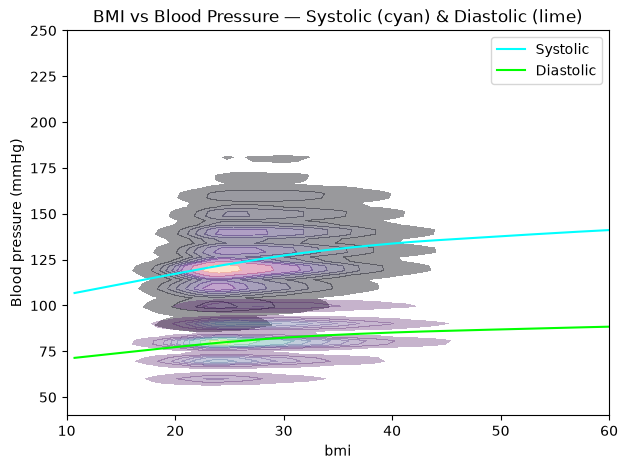

In [54]:
fig, ax1 = plt.subplots(figsize=(7,5))

# Systolic BP
sns.kdeplot(data=medical, x='bmi', y='ap_hi', fill=True, gridsize=80, cmap='magma', alpha=0.4, ax=ax1)
smooth_hi = stm.nonparametric.lowess(medical['ap_hi'], medical['bmi'], delta=0.01 * np.ptp(medical['bmi']))
ax1.plot(smooth_hi[:, 0], smooth_hi[:, 1], color='cyan', label='Systolic')
ax1.set_ylabel('Blood pressure (mmHg)')

# Diastolic BP, using the same mmHg scale
ax2 = ax1
sns.kdeplot(data=medical, x='bmi', y='ap_lo', fill=True, gridsize=80, cmap='viridis', alpha=0.3, ax=ax2)
smooth_lo = stm.nonparametric.lowess(medical['ap_lo'], medical['bmi'], delta=0.01 * np.ptp(medical['bmi']))
ax2.plot(smooth_lo[:, 0], smooth_lo[:, 1], color='lime', label='Diastolic')
ax1.legend()
ax2.set_ylabel('Blood pressure (mmHg)')
plt.xlim(10, 60)
plt.ylim(40, 250)
# Title & style
plt.title("BMI vs Blood Pressure — Systolic (cyan) & Diastolic (lime)")
plt.show()

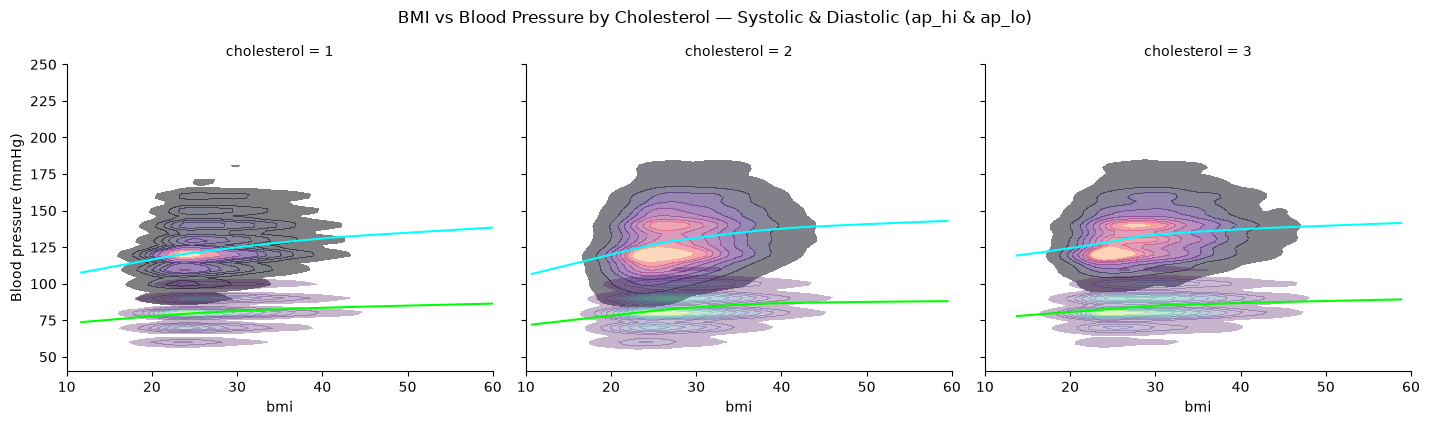

In [55]:
import seaborn as sns
import matplotlib.pyplot as plt

g = sns.FacetGrid(medical, col='cholesterol', height=4, aspect=1.2)


def plot_dual(data, color, **kwargs):
    ax = plt.gca()
    sns.kdeplot(data=data, x='bmi', y='ap_hi', fill=True, gridsize=80, cmap='magma', alpha=0.5, ax=ax)
    smooth = stm.nonparametric.lowess(data['ap_hi'], data['bmi'], delta=0.01 * np.ptp(data['bmi']))
    ax.plot(smooth[:, 0], smooth[:, 1], color='cyan', label='Systolic')
    ax.set_ylabel('Blood pressure (mmHg)')

 
    ax2 = ax
    sns.kdeplot(data=data, x='bmi', y='ap_lo', fill=True, gridsize=80, cmap='viridis', alpha=0.3, ax=ax2)
    smooth = stm.nonparametric.lowess(data['ap_lo'], data['bmi'], delta=0.01 * np.ptp(data['bmi']))
    ax2.plot(smooth[:, 0], smooth[:, 1], color='lime', label='Diastolic')
    ax2.set_ylabel('Blood pressure (mmHg)')
    ax.legend()
    
g.set(xlim=(10, 60), ylim=(40, 250))
g.map_dataframe(plot_dual)
g.fig.suptitle("BMI vs Blood Pressure by Cholesterol — Systolic & Diastolic (ap_hi & ap_lo)", y=1.05)
plt.show()

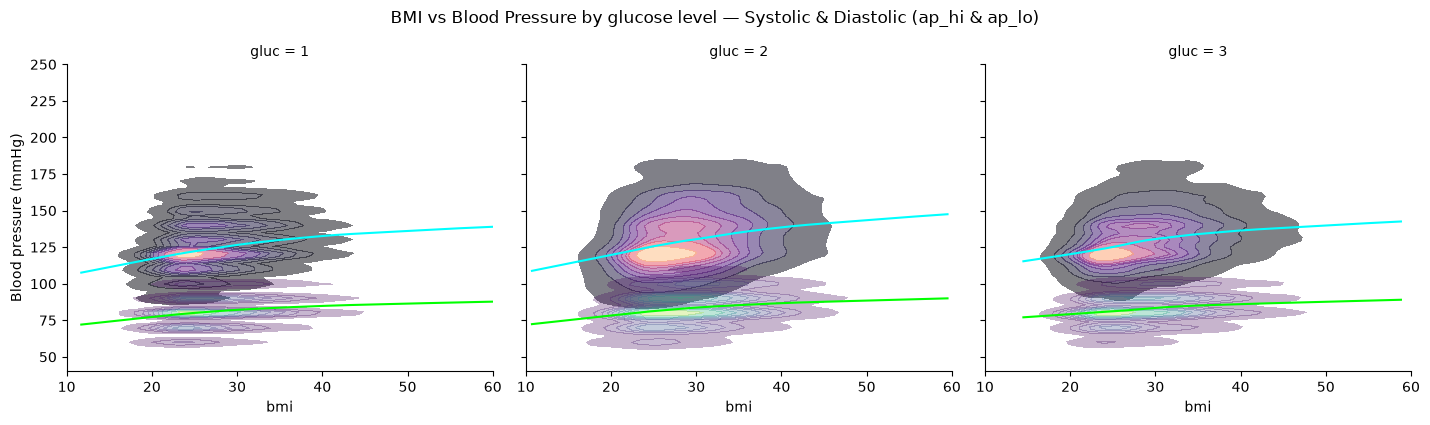

In [56]:
import seaborn as sns
import matplotlib.pyplot as plt
g = sns.FacetGrid(medical, col='gluc', height=4, aspect=1.2)


def plot_dual(data, color, **kwargs):
    ax = plt.gca()
    sns.kdeplot(data=data, x='bmi', y='ap_hi', fill=True, gridsize=80, cmap='magma', alpha=0.5, ax=ax)
    smooth = stm.nonparametric.lowess(data['ap_hi'], data['bmi'], delta=0.01 * np.ptp(data['bmi']))
    ax.plot(smooth[:, 0], smooth[:, 1], color='cyan', label='Systolic')
    ax.set_ylabel('Blood pressure (mmHg)')

 
    ax2 = ax
    sns.kdeplot(data=data, x='bmi', y='ap_lo', fill=True, gridsize=80, cmap='viridis', alpha=0.3, ax=ax2)
    smooth = stm.nonparametric.lowess(data['ap_lo'], data['bmi'], delta=0.01 * np.ptp(data['bmi']))
    ax2.plot(smooth[:, 0], smooth[:, 1], color='lime', label='Diastolic')
    ax2.set_ylabel('Blood pressure (mmHg)')
    ax.legend()
    
g.set(xlim=(10, 60), ylim=(40, 250))
g.map_dataframe(plot_dual)
g.fig.suptitle("BMI vs Blood Pressure by glucose level — Systolic & Diastolic (ap_hi & ap_lo)", y=1.05)
plt.show()

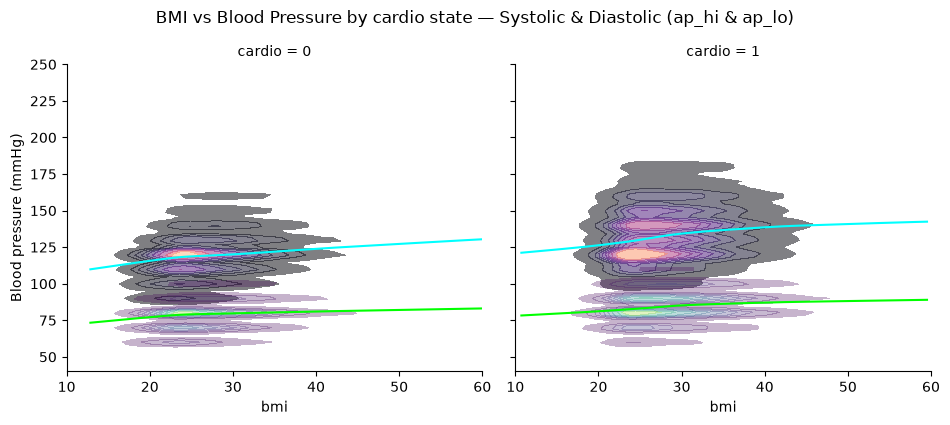

In [57]:
g = sns.FacetGrid(medical, col='cardio', height=4, aspect=1.2)


def plot_dual(data, color, **kwargs):
    ax = plt.gca()
    sns.kdeplot(data=data, x='bmi', y='ap_hi', fill=True, gridsize=80, cmap='magma', alpha=0.5, ax=ax)
    smooth = stm.nonparametric.lowess(data['ap_hi'], data['bmi'], delta=0.01 * np.ptp(data['bmi']))
    ax.plot(smooth[:, 0], smooth[:, 1], color='cyan', label='Systolic')
    ax.set_ylabel('Blood pressure (mmHg)')

 
    ax2 = ax
    sns.kdeplot(data=data, x='bmi', y='ap_lo', fill=True, gridsize=80, cmap='viridis', alpha=0.3, ax=ax2)
    smooth = stm.nonparametric.lowess(data['ap_lo'], data['bmi'], delta=0.01 * np.ptp(data['bmi']))
    ax2.plot(smooth[:, 0], smooth[:, 1], color='lime', label='Diastolic')
    ax2.set_ylabel('Blood pressure (mmHg)')
    ax.legend()
    
g.set(xlim=(10, 60), ylim=(40, 250))
g.map_dataframe(plot_dual)
g.fig.suptitle("BMI vs Blood Pressure by cardio state — Systolic & Diastolic (ap_hi & ap_lo)", y=1.05)
plt.show()

### GAM for modeling

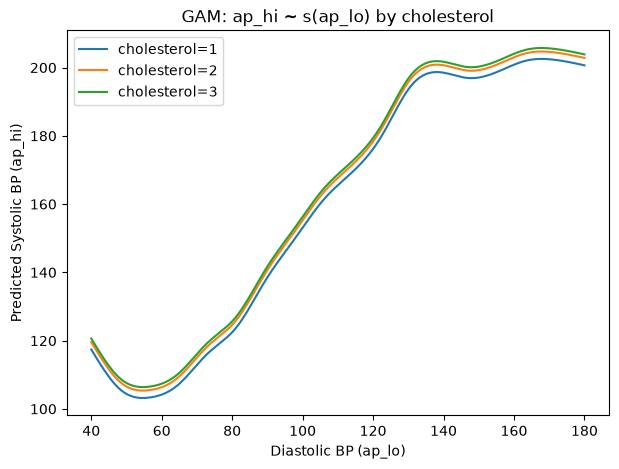

In [58]:
# Fit this model with its own categorical factor.
levels = sorted(medical['cholesterol'].unique())
X = np.column_stack([medical['ap_lo'], medical['cholesterol'] - min(levels)])
gam_cholesterol = LinearGAM(s(0) + f(1)).fit(X, medical['ap_hi'].to_numpy())

import numpy as np
import matplotlib.pyplot as plt

bplo_grid = np.linspace(medical['ap_lo'].min(), medical['ap_lo'].max(), 200)
levels = sorted(medical['cholesterol'].unique())

plt.figure(figsize=(7,5))
for level in levels:
    code = level - min(levels)
    Xgrid = np.column_stack([bplo_grid, np.full_like(bplo_grid, code)])
    yhat = gam_cholesterol.predict(Xgrid)
    plt.plot(bplo_grid, yhat, label=f'cholesterol={level}')

plt.xlabel('Diastolic BP (ap_lo)')
plt.ylabel('Predicted Systolic BP (ap_hi)')
plt.title('GAM: ap_hi ~ s(ap_lo) by cholesterol')
plt.legend()
plt.show()

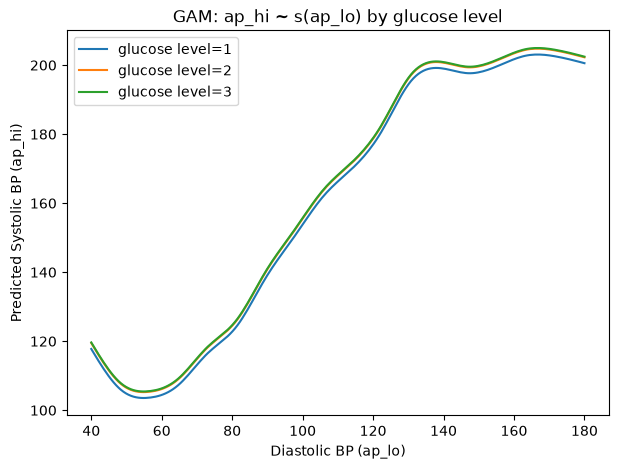

In [59]:
# Fit this model with its own categorical factor.
levels = sorted(medical['gluc'].unique())
X = np.column_stack([medical['ap_lo'], medical['gluc'] - min(levels)])
gam_glucose = LinearGAM(s(0) + f(1)).fit(X, medical['ap_hi'].to_numpy())

bplo_grid = np.linspace(medical['ap_lo'].min(), medical['ap_lo'].max(), 200)
levels = sorted(medical['gluc'].unique())

plt.figure(figsize=(7,5))
for level in levels:
    code = level - min(levels)
    Xgrid = np.column_stack([bplo_grid, np.full_like(bplo_grid, code)])
    yhat = gam_glucose.predict(Xgrid)
    plt.plot(bplo_grid, yhat, label=f'glucose level={level}')

plt.xlabel('Diastolic BP (ap_lo)')
plt.ylabel('Predicted Systolic BP (ap_hi)')
plt.title('GAM: ap_hi ~ s(ap_lo) by glucose level')
plt.legend()
plt.show()

**Generalized Additive Model** offers a Nonlinear smooth relationship between ap_lo and ap_hi, with cholesterol as a categorical factor (f(1)). The other plots use separately fitted models with glucose or cardio as their categorical factor.
It allows a curved (nonlinear) relationship and a flexible local fit rather than a global straight line.
This isn't a statistical test but a **modeling framework**.

The factor adds a constant shift to the smooth curve, so these models share the same curve shape across categories within each plot. These are exploratory fits on the same dataset, not validated predictions on new patients.

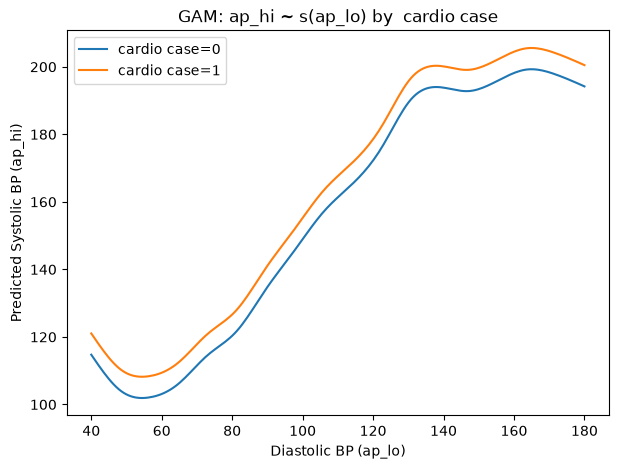

In [60]:
# Fit this model with its own categorical factor.
levels = sorted(medical['cardio'].unique())
X = np.column_stack([medical['ap_lo'], medical['cardio'] - min(levels)])
gam_cardio = LinearGAM(s(0) + f(1)).fit(X, medical['ap_hi'].to_numpy())

bplo_grid = np.linspace(medical['ap_lo'].min(), medical['ap_lo'].max(), 200)
levels = sorted(medical['cardio'].unique())

plt.figure(figsize=(7,5))
for level in levels:
    code = level - min(levels)
    Xgrid = np.column_stack([bplo_grid, np.full_like(bplo_grid, code)])
    yhat = gam_cardio.predict(Xgrid)
    plt.plot(bplo_grid, yhat, label=f'cardio case={level}')

plt.xlabel('Diastolic BP (ap_lo)')
plt.ylabel('Predicted Systolic BP (ap_hi)')
plt.title('GAM: ap_hi ~ s(ap_lo) by  cardio case')
plt.legend()
plt.show()

## Conclusion

In this project we analyzed the 'medical_examination.csv' dataset to explore factors associated with cardiovascular disease.
After some data cleaning: removing rows outside the selected limits, excluding inconsistent blood pressure readings, and creating new variables such as Body Mass Index (BMI) and the arithmetic average of systolic and diastolic pressure. This average is not mean arterial pressure. The dataset was ready for analysis.

The analysis revealed meaningful trends between physiological indicators and recorded cardiovascular disease. Higher BMI categories, elevated cholesterol, elevated glucose levels, and higher blood pressure were all found to be associated with a higher proportion of recorded cardiovascular disease in these unadjusted comparisons. Lifestyle factors such as smoking, alcohol consumption, and physical inactivity showed weaker unadjusted associations with disease status. This does not measure their causal effects on health.

Statistical analyses and correlation measures confirmed significant relationships between these health indicators and cardiovascular conditions.

Overall, this project demonstrates the value of data-driven analysis in identifying and quantifying factors associated with disease status. It also highlights relationships with weight, blood pressure, and metabolic categories, though this dataset alone cannot show how changing them would reduce cardiovascular risk. These results remain exploratory, and possible confounding and the selected cleaning limits should be considered.

## Acknowledgments

Thanks to my teacher, **Yves-André Chapuis**, from **Université de Strasbourg**.

[University staff listing](https://physique-ingenierie.unistra.fr/faculte/enseignants/enseignants-chercheurs/).